# 02 · Tokenization: from text to integers

**What you will learn**
- Why LLMs operate on sub-word tokens rather than characters or words
- How byte-level BPE is trained, how it encodes/decodes, and why it never produces `<UNK>`
- How vocabulary size trades off sequence length against embedding size
- How to *evaluate* a tokenizer: compression ratio, fertility, round-trip correctness

**Source:** `llm_edu_suite/tokenizer.py` (pure Python, ~120 lines).

| Granularity | Vocab | Sequence length | Problem |
|---|---|---|---|
| bytes | 256 | very long | attention is O(T²); the model wastes capacity spelling |
| words | 100k–1M+ | short | unknown words → `<UNK>`; terrible for code and multilingual text |
| **sub-words (BPE)** | 32k–256k | medium | the standard: frequent words = 1 token, rare words = a few pieces |

## Background: why a model needs a vocabulary

A transformer does not read text. Its first layer is an embedding table $E \in \mathbb{R}^{V \times C}$, and its last layer produces $V$ logits, one per vocabulary entry. Everything in between works on vectors indexed by integers in $\{0, \dots, V-1\}$. So before any learning can happen we must fix a function

$$\text{encode}: \text{string} \rightarrow (t_1, \dots, t_n), \quad t_i \in \{0,\dots,V-1\}$$

and its inverse $\text{decode}$. This choice is made once, before pretraining, and it is surprisingly consequential: it decides how long sequences are (and therefore how much attention costs), how many parameters sit in the embedding and output matrices, which languages and domains are cheap or expensive to process, and which tasks the model will find awkward (spelling, arithmetic, counting characters).

### The granularity trade-off

Two forces pull in opposite directions.

- **Short sequences** are good. Attention cost grows as $O(n^2)$ in the number of tokens, the context window is measured in tokens, and every generated token is one forward pass. Fewer tokens per document means cheaper training, cheaper inference and more text fitting in the context.
- **A small, well-trained vocabulary** is also good. Each row of $E$ is learned only from the occurrences of that token. Natural language follows Zipf's law: the frequency of the $r$-th most common word falls roughly like $1/r$, so a word-level vocabulary has a very long tail of words seen a handful of times, whose embeddings are poorly estimated, and any word not in the list becomes `<UNK>`, losing information irrecoverably.

Characters (or bytes) sit at one extreme: tiny vocabulary, no unknowns, but sequences 4 to 5 times longer than with subwords for English, and the model has to spend capacity learning to assemble letters into words. Words sit at the other extreme. Subwords are the compromise: frequent strings get their own token, rare strings are spelled out from smaller pieces, and nothing is ever unknown.

### Subword algorithms: a short history

| method | how the vocabulary is built | segmentation at encode time | used by |
|---|---|---|---|
| **BPE** (Sennrich, Haddow & Birch, 2016) | bottom-up: start from characters, repeatedly merge the most frequent adjacent pair | replay the merges in the order they were learned | GPT family, Llama, Mistral, Qwen |
| **Byte-level BPE** (Radford et al., GPT-2, 2019) | same as BPE, but the base alphabet is the 256 byte values | same | GPT-2 onward, Llama 3, most current decoders |
| **WordPiece** (Schuster & Nakajima, 2012; used in BERT) | bottom-up, merges the pair that most increases corpus likelihood, roughly $\frac{f(ab)}{f(a)f(b)}$, instead of raw frequency | greedy longest-match from the left | BERT and its descendants |
| **Unigram LM** (Kudo, 2018) | top-down: start from a large candidate set and prune pieces whose removal hurts likelihood least | most probable segmentation (Viterbi); can also sample segmentations | T5, ALBERT, XLNet (via SentencePiece) |

BPE itself is older than NLP: Philip Gage described it in 1994 as a data compression scheme. Sennrich et al. noticed that the same merge procedure yields a vocabulary that can represent any word in a fixed budget, which solved the rare-word problem in neural machine translation. **SentencePiece** (Kudo & Richardson, 2018) is not a separate algorithm but a library that implements BPE and Unigram directly on raw text, treating the space as an ordinary symbol (`▁`), so no language-specific word splitting is needed.

### Why byte-level BPE is the industry default

Character-level BPE still has a problem: the base alphabet is every Unicode character in the training data, which for multilingual text plus emoji is enormous, and characters never seen in training are unknown. GPT-2 moved the base alphabet to the **256 possible byte values** of UTF-8. Any string is a sequence of bytes, so any string can be encoded, and decoding the concatenated bytes gives the original text back exactly. The merges then learn which byte sequences are worth a token, which automatically gives multi-byte characters (accents, CJK, emoji) their own tokens when they are frequent enough.

The price is small: a rare character may cost 2 to 4 tokens instead of 1, and a single token can end in the middle of a multi-byte character, so decoding token by token (for streaming output) must buffer incomplete UTF-8 sequences. Most production tokenizers today (tiktoken for OpenAI models, the Llama 3 tokenizer, Qwen's) are byte-level BPE. SentencePiece-based tokenizers, which can run either BPE or Unigram and usually add a *byte fallback* for unseen characters, remain common too (T5, Llama 1 and 2, Gemma).

### What has been tried instead

Tokenization is widely considered an annoyance, and there is active research on removing it. ByT5 (Xue et al., 2022) works directly on bytes and is more robust to noise and spelling but slower; MEGABYTE (Yu et al., 2023) and the Byte Latent Transformer (Pagnoni et al., 2024) group bytes into patches dynamically. None of these has displaced BPE in frontier models yet; whether they will is an open question.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
from llm_edu_suite.tokenizer import ByteBPETokenizer, compression_ratio
from llm_edu_suite.data import template_text_corpus

corpus = template_text_corpus(n_sentences=3000)      # offline English-like text; swap in any .txt you like
print(corpus[:300], "...")
print(f"\ncorpus: {len(corpus):,} chars")

The attention layer encodes the next token without a loss spike. The KV cache stores the input text without a loss spike. The embedding table rotates the validation set in parallel. The KV cache compresses each vector with little memory. A transformer evaluates each vector in one forward pass. The d ...

corpus: 168,406 chars


## Training BPE

Start with 256 byte tokens. Repeatedly find the most frequent adjacent pair and merge it into a new token.
Each merge is a rule `(a, b) -> new_id`; encoding replays the rules in order.

### The algorithm in detail

Write the corpus as a sequence of base symbols $s = (s_1, \dots, s_N)$ with $s_i \in \{0,\dots,255\}$. Training repeats, for $j = 1, \dots, M$ (where $M = V - 256 - \text{number of special tokens}$):

1. Count every adjacent pair: $c(a,b) = \#\{i : s_i = a, s_{i+1} = b\}$.
2. Pick the most frequent pair $(a^*, b^*) = \arg\max_{(a,b)} c(a,b)$ (ties broken deterministically).
3. Create a new symbol $255 + j$, record the rule $(a^*, b^*) \rightarrow 255 + j$ with rank $j$, and replace every occurrence of $a^* b^*$ in $s$ by it.

Each merge shortens the corpus by exactly $c(a^*, b^*)$ symbols, so BPE is a greedy compressor: at every step it takes the single merge that removes the most tokens right now. It is **not** guaranteed to find the vocabulary or the segmentation that gives the shortest encoding overall; it is simply cheap, deterministic and good enough.

**Encoding** a new string repeats the same idea with the learned table: among the adjacent pairs currently present, merge the one with the lowest rank (the earliest learned), and stop when no pair is in the table. Because ranks are fixed, the same text always gives the same tokens.

**Cost.** A naive implementation costs $O(N)$ per merge, $O(NM)$ in total, which is too slow for gigabytes of text. Two standard tricks fix this. First, a regex *pre-tokenizer* splits the text into words and counts each distinct word once, so a step costs $O(U)$ for $U$ unique words rather than $O(N)$, and no merge ever crosses a word boundary. Second, pair counts are updated incrementally after each merge (only the neighbours of merged positions change) and kept in a priority queue. Production libraries (Hugging Face `tokenizers`, `tiktoken`) are written in Rust for the same reason.

### Pre-tokenization

The pre-tokenizer is a regular expression applied before BPE. GPT-2's pattern separates letters, digits, punctuation and whitespace, and keeps a leading space attached to the following word (so `" the"` and `"the"` are different tokens). It exists for two reasons: speed (above), and cleaner tokens, because without it BPE happily learns merges like `"dog."` or `"the cat"` that waste vocabulary on accidental combinations. Later tokenizers refined the regex, for example by limiting how many digits can be merged together, since inconsistent number chunks make arithmetic harder for the model (Llama 1 and 2 split every number into single digits; OpenAI's `cl100k_base` groups up to three digits).

In [3]:
tok = ByteBPETokenizer()
t0 = time.time()
tok.train(corpus, vocab_size=600, verbose=False)
print(f"trained {len(tok.merges)} merges in {time.time() - t0:.1f}s; vocab size {tok.vocab_size} (incl. {len(tok.special)} special tokens)")

# The first merges are the most frequent byte pairs; later merges build whole words.
for (a, b), new_id in list(tok.merges.items())[:8]:
    print(f"merge {new_id}: {tok.vocab[a]!r} + {tok.vocab[b]!r} -> {tok.vocab[new_id]!r}")
print("...")
for (a, b), new_id in list(tok.merges.items())[-5:]:
    print(f"merge {new_id}: {tok.vocab[a]!r} + {tok.vocab[b]!r} -> {tok.vocab[new_id]!r}")

trained 255 merges in 0.0s; vocab size 514 (incl. 3 special tokens)
merge 256: b' ' + b't' -> b' t'
merge 257: b'h' + b'e' -> b'he'
merge 258: b'e' + b's' -> b'es'
merge 259: b'i' + b'n' -> b'in'
merge 260: b'e' + b'r' -> b'er'
merge 261: b'o' + b'r' -> b'or'
merge 262: b' ' + b's' -> b' s'
merge 263: b'e' + b'n' -> b'en'
...
merge 506: b' optim' + b'izer' -> b' optimizer'
merge 507: b' ' + b'K' -> b' K'
merge 508: b' K' + b'V' -> b' KV'
merge 509: b' c' + b'ac' -> b' cac'
merge 510: b' cac' + b'he' -> b' cache'


In [4]:
sentence = "The transformer predicts the next token efficiently."
ids = tok.encode(sentence)
print("ids   :", ids)
print("pieces:", [tok.decode([i]) for i in ids])
print("round-trip exact:", tok.decode(ids) == sentence)
print(f"{len(sentence.encode())} bytes -> {len(ids)} tokens  ({compression_ratio(tok, sentence):.2f} bytes/token)")

# Unseen text still works: it just falls back to smaller pieces, down to raw bytes, so there is never an <UNK>.
weird = "Zyxwvut 🦙 ¿Qué tal? def f(x): return x**2"
print("\nunseen text pieces:", [tok.decode([i]) for i in tok.encode(weird)])
print("round-trip exact:", tok.decode(tok.encode(weird)) == weird)

ids   : [265, 339, 439, 272, 377, 288, 430]
pieces: ['The', ' transformer', ' predicts', ' the', ' next', ' token', ' efficiently.']
round-trip exact: True
52 bytes -> 7 tokens  (7.43 bytes/token)

unseen text pieces: ['Z', 'y', 'x', 'w', 'v', 'ut', ' ', '�', '�', '�', '�', ' ', '�', '�', 'Q', 'u', '�', '�', ' t', 'al', '?', ' d', 'e', 'f', ' ', 'f', '(', 'x', ')', ':', ' r', 'et', 'ur', 'n', ' ', 'x', '*', '*', '2']
round-trip exact: True


## Special tokens and persistence

Special tokens (`<|bos|>`, `<|eos|>`, `<|pad|>`) get the last ids so they can never be produced by a merge.
A tokenizer is frozen *before* pretraining — changing it later means re-learning the embedding table.

### What special tokens are for

Special tokens are symbols the model must be able to recognise with certainty, so they are never produced by merging ordinary text and are inserted only by code.

- **BOS** (beginning of sequence) gives the first real token something to attend to and marks document boundaries when many documents are packed into one training sequence.
- **EOS** (end of sequence) is how the model learns to stop. At generation time, sampling EOS ends the loop.
- **PAD** fills batches of unequal length; its positions are masked out of attention and out of the loss, so the model never learns from it.
- Chat models add role markers (for example `<|im_start|>` and `<|im_end|>` in Qwen's ChatML template). A **chat template** is just a fixed recipe for wrapping messages in these tokens, and using a different template from the one the model was fine-tuned with is a common and silent source of bad outputs.

One security note: if user text containing the literal string `<|eos|>` were encoded as the special token, a user could inject control tokens. Production tokenizers therefore refuse or escape special-token strings in untrusted input unless explicitly allowed.

In [5]:
print("special:", tok.special)
print("with bos/eos:", tok.encode("hello", add_bos=True, add_eos=True))
tok.save(os.path.join(tempfile.gettempdir(), "bpe.json"))
tok2 = ByteBPETokenizer.load(os.path.join(tempfile.gettempdir(), "bpe.json"))
assert tok2.encode(sentence) == ids and tok2.decode(ids) == sentence
print("save/load round-trip OK")

special: {'<|bos|>': 511, '<|eos|>': 512, '<|pad|>': 513}
with bos/eos: [511, 257, 108, 108, 111, 512]
save/load round-trip OK


## Evaluation: how good is a tokenizer?

1. **Round-trip correctness** — `decode(encode(x)) == x` for every input (a hard requirement).
2. **Compression** (bytes per token) on *your* domain — higher is better: shorter sequences = cheaper attention and more effective context.
3. **Fertility** (tokens per word) — a tokenizer trained on English is inefficient on Spanish or code.
4. **Vocabulary size trade-off** — bigger vocab compresses more but makes the embedding/LM-head matrices (`V × C`) heavier.

Below: compression as a function of vocabulary size, and fertility on in-domain vs out-of-domain text.

### The vocabulary-size trade-off in numbers

With model width $C$, the input embedding has $V \cdot C$ parameters and, if the output head is not tied to it, the LM head adds another $V \cdot C$. The final softmax costs $O(V \cdot C)$ per position. For a 7B-class model with $C = 4096$, going from $V = 32{,}000$ to $V = 128{,}000$ adds about $96{,}000 \times 4096 \approx 0.39$B parameters per matrix: noticeable, but small compared to the rest of the network. For a tiny model the same change would dominate the parameter count, which is why small models use small vocabularies.

What you buy is shorter sequences. Compression grows quickly at first (the first merges capture very common pairs like `"th"`, `"e "`) and then slowly, because each new token covers rarer strings. Very large vocabularies also contain tokens that appear so rarely in pretraining that their embeddings stay close to initialisation; these "under-trained" or "glitch" tokens can make models behave strangely when they show up (the `SolidGoldMagikarp` token in GPT-2/3 tokenizers is the famous example, documented by Rumbelow & Watkins in 2023).

| model | vocabulary size |
|---|---|
| GPT-2 | 50,257 |
| Llama 2 | 32,000 |
| Llama 3 | 128,256 |
| Gemma | 256k |

The trend toward larger vocabularies is driven by multilingual and code coverage: with a bigger budget, non-English scripts and programming idioms get their own tokens instead of being spelled out.

### The metrics

- **Compression ratio** (bytes per token, or characters per token) measures how much text one token carries on a given corpus.
- **Fertility** (tokens per word, Rust et al., 2021, "How Good is Your Tokenizer? On the Monolingual Performance of Multilingual Language Models") measures how finely words are split. A fertility near 1 means most words are single tokens; values of 2 to 3 or more mean the language or domain is being spelled out.

These are intrinsic metrics. A tokenizer with better compression is usually, but not always, better for downstream quality; the relationship is debated, and the only definitive test is training models with each tokenizer and comparing them.

### Common failure modes

- **Language unfairness.** A tokenizer trained mostly on English needs many more tokens for the same content in other languages, so those users pay more per request and get less effective context (Petrov et al., 2023, "Language Model Tokenizers Introduce Unfairness Between Languages").
- **Character-level blindness.** The model sees `"strawberry"` as one or a few opaque ids, not ten letters, which is why counting letters or reversing words is hard for LLMs.
- **Arithmetic.** The same number can be split differently depending on context, so digit positions are not aligned between operands.
- **Token boundaries in prompts.** A prompt ending in a space forces the model to continue after a token boundary it rarely saw in training (because spaces usually attach to the next word), which can degrade the first generated tokens.

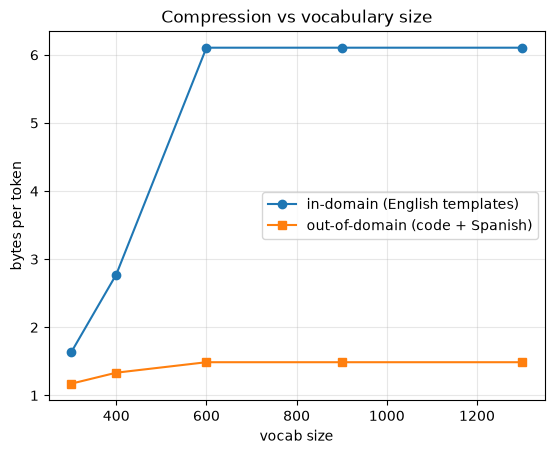

fertility (tokens/word) — in-domain: 1.00   out-of-domain: 3.90


In [6]:
import matplotlib.pyplot as plt

eval_text_in = template_text_corpus(n_sentences=200, seed=123)             # same distribution, but sentences the tokenizer never saw
eval_text_out = ("def attention(q, k, v):\n    return softmax(q @ k.T / sqrt(d)) @ v\n" * 20
                 + "El modelo de lenguaje predice el siguiente token. " * 20)   # code and Spanish, which the tokenizer never saw

sizes = [300, 400, 600, 900, 1300]
ratios_in, ratios_out = [], []
for V in sizes:
    t = ByteBPETokenizer().train(corpus, vocab_size=V)
    ratios_in.append(compression_ratio(t, eval_text_in))
    ratios_out.append(compression_ratio(t, eval_text_out))
    assert t.decode(t.encode(eval_text_out)) == eval_text_out      # decoding must give back the exact text at every size

plt.plot(sizes, ratios_in, "o-", label="in-domain (English templates)")
plt.plot(sizes, ratios_out, "s-", label="out-of-domain (code + Spanish)")
plt.xlabel("vocab size"); plt.ylabel("bytes per token"); plt.title("Compression vs vocabulary size"); plt.legend(); plt.grid(alpha=.3)
plt.show()

def fertility(t, text):
    return len(t.encode(text)) / max(1, len(text.split()))
print(f"fertility (tokens/word) — in-domain: {fertility(tok, eval_text_in):.2f}   out-of-domain: {fertility(tok, eval_text_out):.2f}")

## Results

| question | measured | lesson |
|---|---|---|
| what does training produce? | 255 merges on 168,406 characters → vocabulary 514 (including 3 special tokens); late merges are whole words such as ` optimizer`, ` KV`, ` cache` | BPE learns the frequent strings of its corpus |
| compression in-domain | a 52-byte sentence → 7 tokens (7.43 bytes per token) | in-domain text becomes short sequences |
| unseen characters | emoji, accents and code still round-trip exactly, by falling back to single bytes | byte-level BPE never needs `<UNK>` |
| in-domain vs out-of-domain | fertility 1.00 tokens per word on new English sentences vs 3.90 on code + Spanish | a tokenizer is cheap only on the data it was trained on |
| vocabulary size (plot) | in-domain compression rises and then saturates; out-of-domain text barely benefits | more merges do not help text they were not learned from |

## In production

**What real tokenizers add.**
- A regex pre-tokenizer (no merges across spaces and punctuation), digit splitting (helps arithmetic) and a Rust implementation (`tokenizers`, `tiktoken`, SentencePiece). The algorithm is the one you just ran.
- Large vocabularies trained on multilingual and code mixes: Llama 3 uses 128k tokens, Gemma 256k. This is the fix for the out-of-domain fertility measured above.

**Where tokenization shows up in daily work.**
- Cost and limits: APIs bill and cap context in tokens, so the same request costs more in languages the tokenizer covers poorly.
- Fine-tuning: the chat template and special tokens must match the base model exactly.
- Counting tokens before sending a request, with the model's own tokenizer, not an approximation.

**Failure modes.**
- Mixing up tokenizers between training and serving: no error, just garbage.
- Adding special tokens without resizing the embedding matrix.
- Prompts ending in a trailing space, which splits a token boundary the model rarely saw.
- Expecting letter-level tasks (counting, reversing) to be easy for a model that sees opaque ids.

**Next:** `03_attention_rope_norm.ipynb` — what the model does with these ids.